# A7 — Multi-Model AI Systems

Person 1 supplies the shared contract and SLM foundation. Architecture lead integrates the team evidence, architecture, costs and routing analysis. Original experiments are preserved below. Missing results are explicitly reported.

In [1]:
from pathlib import Path
import sys
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "a7" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from a7.benchmark_contract import (
    EVALUATION_CRITERIA, MODEL_REGISTRY, PROMPTS, render_prompt, validate_contract
)
from a7.benchmark_runner import RESULT_COLUMNS, select_models, validate_result_rows

validate_contract()
print("Shared A7 contract validated.")

Shared A7 contract validated.


## 1. Model registry and allocation

The five fixed A6 size categories contain exactly three models each. Benchmark ownership is distributed 4/4/4/3 by round-robin parameter rank so members do not receive only one size class. All model links point to their Hugging Face cards.

In [2]:
registry_df = pd.DataFrame(MODEL_REGISTRY)
display(registry_df[["category", "model_id", "params_b", "owner", "model_card"]])
display(registry_df.groupby("category").agg(models=("model_id", "count"), min_params_b=("params_b", "min"), max_params_b=("params_b", "max")))
display(registry_df.groupby("owner").agg(models=("model_id", "count"), categories=("category", "nunique")))

,category,model_id,params_b,owner,model_card
0,Ultra-light (<0.2B),distilbert/distilgpt2,0.082,P1,https://huggingface.co/distilbert/distilgpt2
1,Ultra-light (<0.2B),facebook/opt-125m,0.125,P2,https://huggingface.co/facebook/opt-125m
2,Ultra-light (<0.2B),HuggingFaceTB/SmolLM2-135M-Instruct,0.135,P3,https://huggingface.co/HuggingFaceTB/SmolLM2-1...
3,Compact (0.2B–<0.6B),HuggingFaceTB/SmolLM-360M-Instruct,0.360,architecture,https://huggingface.co/HuggingFaceTB/SmolLM-36...
4,Compact (0.2B–<0.6B),HuggingFaceTB/SmolLM2-360M-Instruct,0.360,P1,https://huggingface.co/HuggingFaceTB/SmolLM2-3...
5,Compact (0.2B–<0.6B),Qwen/Qwen2-0.5B-Instruct,0.494,P2,https://huggingface.co/Qwen/Qwen2-0.5B-Instruct
6,Small (0.6B–<1.6B),Qwen/Qwen3-0.6B,0.600,P3,https://huggingface.co/Qwen/Qwen3-0.6B
7,Small (0.6B–<1.6B),TinyLlama/TinyLlama-1.1B-Chat-v1.0,1.100,architecture,https://huggingface.co/TinyLlama/TinyLlama-1.1...
8,Small (0.6B–<1.6B),Qwen/Qwen2.5-1.5B-Instruct,1.540,P1,https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct
9,Medium (1.6B–<3.5B),HuggingFaceTB/SmolLM2-1.7B-Instruct,1.700,P2,https://huggingface.co/HuggingFaceTB/SmolLM2-1...


,models,min_params_b,max_params_b
category,,,
Compact (0.2B–<0.6B),3,0.360,0.494
Large (≥3.5B),3,3.820,7.620
Medium (1.6B–<3.5B),3,1.700,3.210
Small (0.6B–<1.6B),3,0.600,1.540
Ultra-light (<0.2B),3,0.082,0.135


,models,categories
owner,,
P1,4,4
P2,4,4
P3,4,4
architecture,3,3


## 2. Fixed task-specific prompt matrix

Hestia's five prompt types are structured extraction, classification, priority prediction, summarization, and action planning. Each type has five realistic household inputs, producing 25 prompts per model and 375 evaluations overall.

In [3]:
prompts_df = pd.DataFrame(PROMPTS)
prompt_counts = prompts_df.groupby("prompt_type").size().rename("prompts")
display(prompt_counts)
display(prompts_df)
print("Example rendered prompt:\n")
print(render_prompt(PROMPTS[0]))

prompt_type
action_planning          5
classification           5
priority_prediction      5
structured_extraction    5
summarization            5
Name: prompts, dtype: int64

,prompt_id,prompt_type,input
0,extraction-01,structured_extraction,"Guests arrive tomorrow. Clean the kitchen, buy..."
1,extraction-02,structured_extraction,"This week I need to book the dentist, replace ..."
2,extraction-03,structured_extraction,"Before Saturday, vacuum the living room and pi..."
3,extraction-04,structured_extraction,Please remind us to pay the electricity bill t...
4,extraction-05,structured_extraction,The refrigerator is making noise. Also organiz...
5,classification-01,classification,Buy milk and rice after work.
6,classification-02,classification,Call the plumber about the dripping kitchen pipe.
7,classification-03,classification,Schedule a yearly dental cleaning.
8,classification-04,classification,Submit the apartment renewal form by Friday.
9,classification-05,classification,Sweep the porch and empty the recycling.


Example rendered prompt:

You are Hestia, a household coordination assistant. Do not invent private details or claim that an action is complete.
Return JSON only: {"tasks":[{"title":"...","task_type":"CHORE|APPOINTMENT|DEADLINE|ERRAND|MAINTENANCE|SHOPPING|OTHER","priority":"LOW|MEDIUM|HIGH|URGENT","description":"..."}]}. Create one task per concern.
Household request: Guests arrive tomorrow. Clean the kitchen, buy snacks, and fix the leaking bathroom tap.
Answer:


## 3. Self-evaluation rubric

Every raw output is reviewed against the same five criteria. Criterion points sum to 10. The reproducible first pass checks exact labels, JSON shape, task-specific concept coverage, clarity, and unsupported details. Person 1 inspects the raw output and review note beside each score; latency and model size do not influence quality.

In [4]:
rubric_df = pd.DataFrame(EVALUATION_CRITERIA)
display(rubric_df)
print("Maximum score:", rubric_df["max_points"].sum())

,criterion,max_points,description
0,task_accuracy,3,Correctly addresses the household request with...
1,instruction_adherence,2,Follows the requested task and output instruct...
2,completeness,2,Includes all essential requested information.
3,clarity,2,"Produces concise, understandable, usable text."
4,no_unsupported_details,1,"Avoids invented facts, dates, people, or requi..."


Maximum score: 10


## 4. Person 1 experiment

Person 1 runs four models across four size categories on the same Apple MPS environment. The runner uses deterministic greedy generation with a fixed 220-token limit, checkpoints after each response, and records latency, generated tokens, and tokens per second.

In [5]:
person1_models = select_models(owner="P1")
display(pd.DataFrame(person1_models)[["category", "model_id", "params_b", "model_card"]])
print("Expected evaluations:", len(person1_models) * len(PROMPTS))

,category,model_id,params_b,model_card
0,Ultra-light (<0.2B),distilbert/distilgpt2,0.082,https://huggingface.co/distilbert/distilgpt2
1,Compact (0.2B–<0.6B),HuggingFaceTB/SmolLM2-360M-Instruct,0.360,https://huggingface.co/HuggingFaceTB/SmolLM2-3...
2,Small (0.6B–<1.6B),Qwen/Qwen2.5-1.5B-Instruct,1.540,https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct
3,Large (≥3.5B),microsoft/Phi-3.5-mini-instruct,3.820,https://huggingface.co/microsoft/Phi-3.5-mini-...


Expected evaluations: 100


In [6]:
# Change to True only when intentionally regenerating all Person 1 evidence.
RUN_PERSON1_BENCHMARK = False
RESULT_PATH = REPO_ROOT / "a7" / "results" / "person1_benchmark.csv"

if RUN_PERSON1_BENCHMARK:
    from a7.benchmark_runner import run_matrix
    rows = run_matrix(person1_models, RESULT_PATH, device_request="auto", max_new_tokens=220)
    print(f"Saved {len(rows)} raw evaluations to {RESULT_PATH}")
else:
    print("Using the checked-in Person 1 evidence; generation is disabled in this notebook run.")

Using the checked-in Person 1 evidence; generation is disabled in this notebook run.


## 5. Evidence review and summary

The checked-in CSV contains actual raw outputs and completed rubric fields. The cell below validates the exact 100-row Person 1 matrix, confirms the common generation limit, shows every response and review note, and summarizes measured speed and quality.

In [7]:
if RESULT_PATH.exists():
    person1_results = pd.read_csv(RESULT_PATH, keep_default_na=False)
    validate_result_rows(person1_results.to_dict("records"), person1_models, PROMPTS)
    numeric = ["latency_seconds", "output_tokens", "tokens_per_second", "self_evaluation_score_1_to_10", "max_new_tokens"]
    for column in numeric:
        person1_results[column] = pd.to_numeric(person1_results[column], errors="coerce")
    assert len(person1_results) == 100
    assert person1_results["status"].eq("ok").all()
    assert person1_results["self_evaluation_score_1_to_10"].notna().all()
    assert set(person1_results["max_new_tokens"]) == {220}
    display(person1_results)
    person1_summary = person1_results.groupby(["model_category", "model_id"]).agg(
        evaluations=("prompt_id", "count"),
        mean_latency_seconds=("latency_seconds", "mean"),
        mean_tokens_per_second=("tokens_per_second", "mean"),
        mean_quality=("self_evaluation_score_1_to_10", "mean"),
    ).round(3)
    display(person1_summary)
else:
    raise FileNotFoundError("Run the Person 1 benchmark before submission.")

,model_id,model_category,owner,prompt_id,prompt_type,prompt,latency_seconds,output_tokens,tokens_per_second,generated_output,...,device,max_new_tokens,generated_at_utc,task_accuracy_0_to_3,instruction_adherence_0_to_2,completeness_0_to_2,clarity_0_to_2,no_unsupported_details_0_to_1,self_evaluation_score_1_to_10,review_notes
0,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-01,structured_extraction,"Guests arrive tomorrow. Clean the kitchen, buy...",1.1112,220,197.9886,"""No, you're not here. You're here. You're here...",...,mps,220,2026-10-23T17:28:35.817226+00:00,0,0,0,0,0,1,Covered 0/3 concerns; JSON task schema invalid...
1,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-02,structured_extraction,"This week I need to book the dentist, replace ...",0.8068,220,272.6956,I am not a dentist. I am a dentist. I am a den...,...,mps,220,2026-10-23T17:28:36.626639+00:00,1,0,1,0,1,3,Covered 1/4 concerns; JSON task schema invalid...
2,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-03,structured_extraction,"Before Saturday, vacuum the living room and pi...",1.2996,220,169.2817,"If you have a problem with the door, you can c...",...,mps,220,2026-10-23T17:28:37.927594+00:00,3,0,2,1,1,7,Covered 3/3 concerns; JSON task schema invalid.
3,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-04,structured_extraction,Please remind us to pay the electricity bill t...,0.7790,220,282.4291,We are not responsible for the amount of elect...,...,mps,220,2026-10-23T17:28:38.707972+00:00,1,0,1,0,1,3,Covered 1/3 concerns; JSON task schema invalid...
4,distilbert/distilgpt2,Ultra-light (<0.2B),P1,extraction-05,structured_extraction,The refrigerator is making noise. Also organiz...,0.8053,220,273.1813,The refrigerator is making noise. Also organiz...,...,mps,220,2026-10-23T17:28:39.514719+00:00,3,0,2,0,1,6,Covered 3/3 concerns; JSON task schema invalid...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),P1,planning-01,action_planning,Prepare the apartment for overnight guests tom...,19.5454,220,11.2558,"{""steps"":[""Step 1: Ensure all cleaning supplie...",...,mps,220,2026-10-23T17:34:22.115928+00:00,3,0,2,1,1,7,Covered 3/3 planning concepts; 3–5 step JSON i...
96,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),P1,planning-02,action_planning,Organize a weekly grocery trip while staying u...,20.4956,220,10.7340,"{""steps"":[""Step 1: Create a grocery list categ...",...,mps,220,2026-10-23T17:34:42.614711+00:00,3,0,2,1,1,7,Covered 3/3 planning concepts; 3–5 step JSON i...
97,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),P1,planning-03,action_planning,Deep-clean the kitchen safely in one afternoon.,14.6461,168,11.4706,"{""steps"":[""Step 1: Gather all necessary cleani...",...,mps,220,2026-10-23T17:34:57.266686+00:00,3,2,2,2,1,10,Covered 4/4 planning concepts; 3–5 step JSON v...
98,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),P1,planning-04,action_planning,Get ready for a move to a new apartment next m...,20.0580,220,10.9682,"{""steps"":[""Step 1: Create a detailed checklist...",...,mps,220,2026-10-23T17:35:17.327996+00:00,3,0,2,1,1,7,Covered 4/4 planning concepts; 3–5 step JSON i...


,,evaluations,mean_latency_seconds,mean_tokens_per_second,mean_quality
model_category,model_id,,,,
Compact (0.2B–<0.6B),HuggingFaceTB/SmolLM2-360M-Instruct,25,1.602,49.959,3.84
Large (≥3.5B),microsoft/Phi-3.5-mini-instruct,25,10.567,10.551,7.32
Small (0.6B–<1.6B),Qwen/Qwen2.5-1.5B-Instruct,25,2.635,19.647,7.56
Ultra-light (<0.2B),distilbert/distilgpt2,25,0.836,268.325,2.28


## 6. Person 1 preliminary findings and final-analysis status

Across Person 1's four assigned models, **Qwen2.5-1.5B-Instruct** produced the highest mean rubric score (7.56/10) and the best measured speed/quality balance (19.65 generated tokens/second, 2.63-second mean latency). Phi-3.5 Mini was slower (10.55 tokens/second, 10.57-second mean latency) and scored 7.32/10, so this subset does **not** support the claim that a larger model always performs better. DistilGPT2 was fastest (268.33 tokens/second) but had the lowest quality (2.28/10), showing the tradeoff between raw throughput and instruction-following quality.

These are **preliminary four-model findings**, not the assignment's final conclusions. Person 1 will answer the required best-category, size-versus-quality, and speed/quality questions again after the other members return their reviewed CSVs and all 375 rows are merged. The final analysis must use all 15 models.

## Assignment 2 — Person 1 SLM experiments

The class notebook has now been supplied. `slm/slm_experiments.ipynb` contains the
executed original baseline, five independent architecture experiments, four
temperature tests and evidence-based Part 1 analysis. The original class source is
preserved in `slm/class_source.ipynb`; `slm/HANDOFF.md` explains how Persons 2 and 3
load the same selected baseline checkpoint. Weight files are not committed.

## Architecture lead — integrated evidence and coverage

Successful, reviewed results are required for all 375 model/prompt pairs. A failed download is not an evaluated response. Timings from different machines are not directly comparable, even if both use the same device label.

In [8]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'a7/benchmark_contract.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from a7.architecture_analysis import write_analysis
data, coverage, models, categories, costs, cost_status = write_analysis(ROOT)
display(coverage)
print('Successful evaluations:', int(coverage.successful.sum()), '/ 375')
print('Scored successful evaluations:', int(coverage.scored.sum()), '/ 375')
display(models)
display(categories)


,owner,expected,recorded,successful,scored,missing,remaining_successful
0,P1,100,100,100,100,0,0
1,P2,100,0,0,0,100,100
2,P3,100,0,0,0,100,100
3,architecture,75,75,50,50,0,25


Successful evaluations: 150 / 375
Scored successful evaluations: 150 / 375


,model_id,model_category,device,max_new_tokens,evaluations,scored,mean_quality,median_latency_s,p95_latency_s,median_tokens_s
0,HuggingFaceTB/SmolLM-360M-Instruct,Compact (0.2B–<0.6B),cpu,220,25,25,2.48,19.0588,19.95602,11.4717
1,HuggingFaceTB/SmolLM2-360M-Instruct,Compact (0.2B–<0.6B),mps,220,25,25,3.84,0.5633,4.17766,50.8544
2,Qwen/Qwen2.5-1.5B-Instruct,Small (0.6B–<1.6B),mps,220,25,25,7.56,1.5895,7.66020,22.0191
3,TinyLlama/TinyLlama-1.1B-Chat-v1.0,Small (0.6B–<1.6B),cuda,220,25,25,2.96,5.2453,5.91038,37.7479
4,distilbert/distilgpt2,Ultra-light (<0.2B),mps,220,25,25,2.28,0.7815,1.10786,281.5080
5,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),mps,220,25,25,7.32,5.3627,20.49218,10.8810


,model_category,models,evaluations,scored,mean_quality,expected_evaluations
0,Compact (0.2B–<0.6B),2,50,50,3.16,75
1,Large (≥3.5B),1,25,25,7.32,75
2,Small (0.6B–<1.6B),2,50,50,5.26,75
3,Ultra-light (<0.2B),1,25,25,2.28,75


### Step 1.6: performance analysis

Category means are preliminary until each category has 75 successful reviewed evaluations. Determine whether larger models always win by checking matched prompts, not by assuming parameter count determines quality. The best speed/quality choice must satisfy the task quality threshold and be timed on the same hardware. The next cell shows available evidence without declaring a global speed winner.

In [9]:
if not models.empty:
    display(models.sort_values('mean_quality', ascending=False))
    display(data[data.status.eq('ok')].groupby(['model_id', 'prompt_type'])[
        'self_evaluation_score_1_to_10'].agg(['count', 'mean']))
if coverage.successful.sum() < 375 or coverage.scored.sum() < 375:
    print('PENDING: complete and manually review all team results before final conclusions.')


,model_id,model_category,device,max_new_tokens,evaluations,scored,mean_quality,median_latency_s,p95_latency_s,median_tokens_s
2,Qwen/Qwen2.5-1.5B-Instruct,Small (0.6B–<1.6B),mps,220,25,25,7.56,1.5895,7.66020,22.0191
5,microsoft/Phi-3.5-mini-instruct,Large (≥3.5B),mps,220,25,25,7.32,5.3627,20.49218,10.8810
1,HuggingFaceTB/SmolLM2-360M-Instruct,Compact (0.2B–<0.6B),mps,220,25,25,3.84,0.5633,4.17766,50.8544
3,TinyLlama/TinyLlama-1.1B-Chat-v1.0,Small (0.6B–<1.6B),cuda,220,25,25,2.96,5.2453,5.91038,37.7479
0,HuggingFaceTB/SmolLM-360M-Instruct,Compact (0.2B–<0.6B),cpu,220,25,25,2.48,19.0588,19.95602,11.4717
4,distilbert/distilgpt2,Ultra-light (<0.2B),mps,220,25,25,2.28,0.7815,1.10786,281.5080


count  mean
model_id                            prompt_type                       
HuggingFaceTB/SmolLM-360M-Instruct  action_planning            5   2.8
                                    classification             5   1.0
                                    priority_prediction        5   1.0
                                    structured_extraction      5   3.2
                                    summarization              5   4.4
HuggingFaceTB/SmolLM2-360M-Instruct action_planning            5   5.4
                                    classification             5   1.0
                                    priority_prediction        5   1.0
                                    structured_extraction      5   6.6
                                    summarization              5   5.2
Qwen/Qwen2.5-1.5B-Instruct          action_planning            5   8.2
                                    classification             5   6.4
                                    priority_prediction        5   4.6
                                    structured_extraction      5  10.0
                                    summarization              5   8.6
TinyLlama/TinyLlama-1.1B-Chat-v1.0  action_planning            5   4.0
                                    classification             5   1.0
                                    priority_prediction        5   1.0
                                    structured_extraction      5   3.2
                                    summarization              5   5.6
distilbert/distilgpt2               action_planning            5   1.8
                                    classification             5   1.0
                                    priority_prediction        5   1.0
                                    structured_extraction      5   4.0
                                    summarization              5   3.6
microsoft/Phi-3.5-mini-instruct     action_planning            5   7.6
                                    classification             5   8.2
                                    priority_prediction        5   3.8
                                    structured_extraction      5   8.8
                                    summarization              5   8.2

PENDING: complete and manually review all team results before final conclusions.


## Architecture lead — Steps 2.5 and 3.1–3.3

The full five-scenario design and cost methodology are in `system_design.md`. Real cost comparison waits for two normalized 90-row team tables. Routing load simulations below use explicit planning assumptions, not measured traffic or inferred savings.

In [10]:
from a7.architecture_analysis import crossover_intervals, routing_simulation
print(cost_status)
if not costs.empty:
    display(costs)
    display(crossover_intervals(costs))
    display(costs.groupby(['model_id', 'cheaper']).daily_active_users.apply(list))
simulation = routing_simulation()
display(simulation)


Pending Person 2 local_costs.csv and Person 3 api_costs.csv.


,traffic_category,daily_active_users,scenario,assumed_requests_per_user,assumed_output_tokens,assumed_cache_fraction,assumed_local_fraction,assumed_api_fraction,assumed_peak_factor,cached_requests,local_requests,api_requests,local_output_tokens,api_output_tokens,peak_generation_requests_s,evidence_type
0,Prototype,1000,Normal operation,1,500,0.10,0.65,0.25,1,100.0,650.0,250.0,3.250000e+05,1.250000e+05,0.010417,illustrative planning assumptions
1,Prototype,1000,Evening peak,1,500,0.10,0.50,0.40,4,100.0,500.0,400.0,2.500000e+05,2.000000e+05,0.041667,illustrative planning assumptions
2,Prototype,1000,Complex household plan,1,500,0.05,0.15,0.80,1,50.0,150.0,800.0,7.500000e+04,4.000000e+05,0.010995,illustrative planning assumptions
3,Prototype,1000,Budget pressure,1,500,0.20,0.70,0.10,1,200.0,700.0,100.0,3.500000e+05,5.000000e+04,0.009259,illustrative planning assumptions
4,Prototype,1000,Local overload,1,500,0.10,0.10,0.80,4,100.0,100.0,800.0,5.000000e+04,4.000000e+05,0.041667,illustrative planning assumptions
5,Early Startup,10000,Normal operation,1,500,0.10,0.65,0.25,1,1000.0,6500.0,2500.0,3.250000e+06,1.250000e+06,0.104167,illustrative planning assumptions
6,Early Startup,10000,Evening peak,1,500,0.10,0.50,0.40,4,1000.0,5000.0,4000.0,2.500000e+06,2.000000e+06,0.416667,illustrative planning assumptions
7,Early Startup,10000,Complex household plan,1,500,0.05,0.15,0.80,1,500.0,1500.0,8000.0,7.500000e+05,4.000000e+06,0.109954,illustrative planning assumptions
8,Early Startup,10000,Budget pressure,1,500,0.20,0.70,0.10,1,2000.0,7000.0,1000.0,3.500000e+06,5.000000e+05,0.092593,illustrative planning assumptions
9,Early Startup,10000,Local overload,1,500,0.10,0.10,0.80,4,1000.0,1000.0,8000.0,5.000000e+05,4.000000e+06,0.416667,illustrative planning assumptions


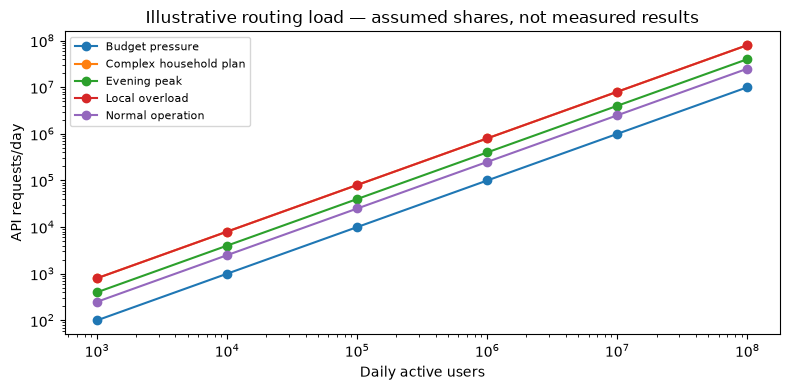

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
for scenario, group in simulation.groupby('scenario'):
    ax.plot(group.daily_active_users, group.api_requests, marker='o', label=scenario)
ax.set(xscale='log', yscale='log', xlabel='Daily active users', ylabel='API requests/day',
       title='Illustrative routing load — assumed shares, not measured results')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Submission status

Architecture lead benchmark: see coverage above. Cost crossover and full-team performance conclusions remain pending missing inputs. Assignment 2 Part 4 is in `slm/architecture_comparison.ipynb` and a Markdown section of the submitted `slm/slm_experiments.ipynb`. Checkpoints are excluded from submission.